In [1]:
# import squidpy as sd
import scanpy as sc
# import pandas as pd
import numpy as np
# import anndata as ad
from spatialdata_io import xenium
import spatialdata as sd
import spatialdata_plot
import matplotlib.pyplot as plt
from pyprojroot import here
import pickle


/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatial

In [2]:
# initialize an empty set of figures for later rendering in more structured reports
figures = {}

This notebook walks you through standard QC of Xenium data. This notebook will not cover region selection. It is assumed you are using this to check an entire sample, which can later be analyzed with a narrower focus. 

Some of this code is adapted from [10x's analysis guide](https://www.10xgenomics.com/analysis-guides/xenium-downstream-analysis-in-python-tutorial)

# Load data

In [3]:
## if you have proseg cell boundaries, add these flags (https://github.com/dcjones/proseg/issues/75)
## , cells_labels=False, nucleus_boundaries=False
sdata = xenium(here("02_data/03_processed-data/XE055_48793_CTP25-024"), cells_labels=False, nucleus_boundaries=False)
sdata

INFO     reading                                                                                                   
         /fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/02_data/03_processed-data
         /XE055_48793_CTP25-024/cell_feature_matrix.h5                                                             


/loc/scratch/30615751/ipykernel_12645/4226094114.py:3: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(here("02_data/03_processed-data/XE055_48793_CTP25-024"), cells_labels=False, nucleus_boundaries=False)
/home/dgratz/.local/share/uv/python/cpython-3.13.2-linux-x86_64-gnu/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata_io/_utils.py:47: UserWarning: The "cell_id" column in the cells metadata table does not match the "cell_id" column in the annotation table. This could be due to trying to read a new version that is not supported yet. Please report this issue.
  return f(*args, **kwargs)


SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (1, 10297, 34105), (1, 5148, 17052), (1, 2574, 8526), (1, 1287, 4263), (1, 643, 2131)
├── Labels
│     └── 'nucleus_labels': DataTree[yx] (10297, 34105), (5148, 17052), (2574, 8526), (1287, 4263), (643, 2131)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (18014, 1) (2D shapes)
│     └── 'cell_circles': GeoDataFrame shape: (18014, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (18014, 480)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes)

Preview your tissue and the transcript recovery per cell. Check for any unexpected ommisions.

In [ ]:
sdata.tables["table"].obs["region"] = "cell_boundaries"
sdata.set_table_annotates_spatialelement("table", region="cell_boundaries")

# The x and y axis are pixel coordinates
figures['transcript_overlay'] = sdata.pl.render_shapes("cell_boundaries", color="total_counts")
figures['transcript_overlay'].pl.show()


/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata/_core/spatialdata.py:511: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)


SpatialData object
├── Images
│     └── 'morphology_focus': DataTree[cyx] (1, 10297, 34105), (1, 5148, 17052), (1, 2574, 8526), (1, 1287, 4263), (1, 643, 2131)
├── Labels
│     └── 'nucleus_labels': DataTree[yx] (10297, 34105), (5148, 17052), (2574, 8526), (1287, 4263), (643, 2131)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (18014, 1) (2D shapes)
│     └── 'cell_circles': GeoDataFrame shape: (18014, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (17653, 426)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), nucleus_labels (Labels), transcripts (Points), cell_boundaries (Shapes), cell_circles (Shapes)

The spatial object contains images and cell boundary definitions, which take up a lot of space. We mostly work with the single-cell like anndata object. 

In [5]:
adata = sdata["table"]
# We store the raw counts in the layers in case we need it for future purposes
adata.layers["counts"] = adata.X.copy()

# Filtering cells

We want to remove cells with low transcript counts. Here we plot the distribution of transcript counts per cell in a histogram to determine the transcript count cutoff to remove cells with low transcript counts. The determination of lower cutoff can be subjective. There is no gold-standard rule. 

Text(0, 0.5, 'Number of cells')

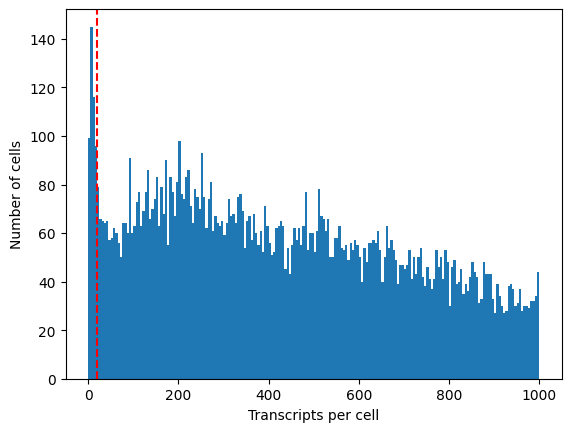

In [6]:
## Apply a hard cutoff for transcripts per cell, or use a quantile-based approach
thres = np.quantile(adata.obs["total_counts"], 0.98)
# thres = 20

fig = plt.hist(adata.obs["total_counts"], range=(0, 1000), bins=200)
plt.axvline(x=20, color="r", linestyle="--")

plt.xlabel("Transcripts per cell")
plt.ylabel("Number of cells")

In [7]:
sc.pp.filter_cells(adata, max_counts=thres)

## TODO: implement a nMAD approach for outlier detection

# Feature selection

In [8]:
thresh = min(np.round(adata.n_obs*0.005), 100) ## 100 cells or 0.5% of the data, whichever is fewer

In [9]:
# We also filter out genes that are rarely expressed
# Adjust this value based on the # of cells in your sample
sc.pp.filter_genes(adata, min_cells=thresh)

If you have a large panel (>2k genes), defining highly variable genes is needed for downstream dimensional reduction

In [10]:
if adata.n_vars > 2000:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000)
else:
    print(f"Only {adata.n_vars} genes in the panel, not defining highly variable genes")

Only 426 genes in the panel, not defining highly variable genes


# Normalize, log-transform, and scale

In [11]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()

In [12]:
# Scaling of data, we don't center the data here as the data centering is done in PCA and this keeps the X sparse for memory efficiency.
sc.pp.scale(adata, zero_center=False, max_value=10)

In [13]:
# PCA for dimension reduction further by UMAP for downstream analysis
sc.pp.pca(adata, n_comps=30)
sc.pp.neighbors(adata, metric="cosine")
# clustering with leiden. We use igraph here as it scales better. The resolution is a hyper-parameter. A higher resolution will output more clusters.
sc.tl.leiden(adata, flavor="igraph", n_iterations=-1, resolution=0.5)

# UMAP

In [14]:
## this may take a while
sc.tl.umap(adata)

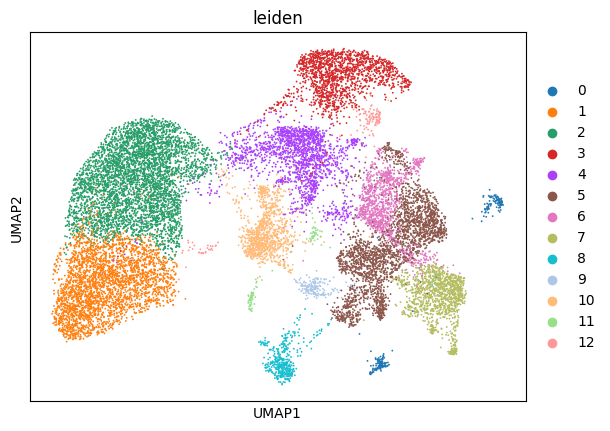

In [ ]:
figures['cluster_umap'] = sc.pl.umap(adata, color="leiden", show=False)

Visualize clusters in the tissue

In [41]:
figures['cluster_umap']

<Axes: title={'center': 'leiden'}, xlabel='UMAP1', ylabel='UMAP2'>

/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata/_core/spatialdata.py:511: UserWarning: Converting `region_key: region` to categorical dtype.
  convert_region_column_to_categorical(table)


INFO     Using 'datashader' backend with 'None' as reduction method to speed up plotting. Depending on the         
         reduction method, the value range of the plot might change. Set method to 'matplotlib' do disable this    
         behaviour.                                                                                                


/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata/_core/_elements.py:105: UserWarning: Key `cell_boundaries` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata/_core/_elements.py:125: UserWarning: Key `table` already exists. Overwriting it in-memory.
  self._check_key(key, self.keys(), self._shared_keys)
/fh/fast/_IRC/FHIL/grp/inhouse_computational_resources/analysis_project_template/.venv/lib/python3.13/site-packages/spatialdata_plot/pl/utils.py:775: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)

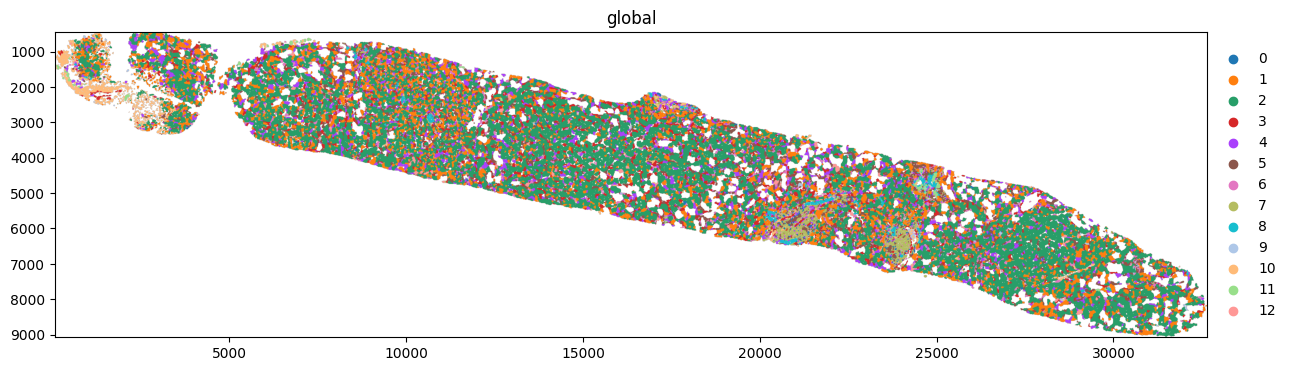

In [16]:
sdata.tables["table"].obs["region"] = "cell_boundaries"
sdata.set_table_annotates_spatialelement("table", region="cell_boundaries")

figures['cluster_gridplot'] = sdata.pl.render_shapes("cell_boundaries", color="leiden").pl.show(figsize=(12.8, 9.6))
figures['cluster_gridplot']

If you want more clusters (e.g, you see more refined morphology that you want to capture), increase the resolution in the `sc.tl.leiden` call. However for a first pass QC check, any value between 10 and 50 should be fine. You're mostly just looking to see if you are capturing any difference in physiology. You can always recluster or subcluster later as needed.

# Save

In [17]:
# sdata.write("breast_processed.zarr", overwrite=True)
## Alternatively, could just save the adata for lighter footprint
# adata.write(here('03_analysis/04_checkpoints/01_qc-filtered.h5ad'))


write figures for QMD document

In [20]:
with open(here("05_dissemination/reports/object_stores/01_figures.pkl"), "wb") as fo:
    pickle.dump(figures, fo)